# Žastikaulio lūžių analizės RAG sistema naudojant „ChromaDB“ ir „Gemini API“

Šiame „Google Colab“ dokumente ankstesnis end-to-end DI agentas papildomas RAG metodu. Sistemoje naudojama ne mažiau kaip 1 000 žastikaulio rentgenogramų `(X, y)` pavyzdžių.

Kiekvienai rentgenogramai sukuriamas skaitinis vaizdo embeddingas, kuris kartu su žinoma klase `y` išsaugomas „ChromaDB“ vektorių duomenų bazėje. Gavusi naują rentgenogramą `X`, sistema suranda tris panašiausius pavyzdžius. Šių pavyzdžių rezultatai įtraukiami į išplėstą promptą, kuris perduodamas „Gemini“ modeliui galutiniam rezultatui `Y` sugeneruoti.

Proceso etapai:

`Nauja įvestis X → embeddingo sukūrimas → 3 panašiausių pavyzdžių paieška → išplėsto prompto formavimas → Gemini analizė → rezultatas Y`

Sistema sukurta mokymosi ir tyrimo tikslams. Jos rezultatai nėra medicininė diagnozė.

In [3]:
from google.colab import drive
from pathlib import Path
import pandas as pd

# Prijungiamas Google Drive
drive.mount("/content/drive")

# MURA duomenų rinkinio vieta
MURA_DIR = Path("/content/drive/MyDrive/Magistras/Dataset/MURA-v1.1")

if not MURA_DIR.exists():
    raise FileNotFoundError(f"Nerastas MURA katalogas: {MURA_DIR}")

print("✅ MURA duomenų katalogas rastas:")
print(MURA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ MURA duomenų katalogas rastas:
/content/drive/MyDrive/Magistras/Dataset/MURA-v1.1


In [4]:
import pandas as pd
from pathlib import Path

records = []

# Tik konkretūs žastikaulio katalogai
humerus_dirs = [
    ("train", MURA_DIR / "train" / "XR_HUMERUS"),
    ("valid", MURA_DIR / "valid" / "XR_HUMERUS")
]

for split, humerus_dir in humerus_dirs:
    if not humerus_dir.exists():
        print(f"⚠️ Katalogas nerastas: {humerus_dir}")
        continue

    print(f"Skaitomas katalogas: {humerus_dir}")

    for image_path in humerus_dir.glob("*/*/*.png"):
        path_text = str(image_path).lower()

        if "positive" in path_text:
            label = 1
            meaning = "anomalija"
        elif "negative" in path_text:
            label = 0
            meaning = "anomalijos nėra"
        else:
            continue

        records.append({
            "X": str(image_path),
            "y": label,
            "reiksme": meaning,
            "split": split
        })

mura_df = pd.DataFrame(records)

print(f"\n✅ Rasta XR_HUMERUS rentgenogramų: {len(mura_df)}")

print("\nKlasių pasiskirstymas:")
display(
    mura_df["y"].value_counts().rename({
        0: "y = 0 – anomalijos nėra",
        1: "y = 1 – anomalija"
    })
)

print("\nDuomenų padalijimas:")
display(mura_df["split"].value_counts())

print("\nPirmi (X, y) pavyzdžiai:")
display(mura_df.head())

Skaitomas katalogas: /content/drive/MyDrive/Magistras/Dataset/MURA-v1.1/train/XR_HUMERUS
Skaitomas katalogas: /content/drive/MyDrive/Magistras/Dataset/MURA-v1.1/valid/XR_HUMERUS

✅ Rasta XR_HUMERUS rentgenogramų: 1686

Klasių pasiskirstymas:


,count
y,
y = 1 – anomalija,865
y = 0 – anomalijos nėra,821



Duomenų padalijimas:


,count
split,
train,1272
valid,414



Pirmi (X, y) pavyzdžiai:


,X,y,reiksme,split
0,/content/drive/MyDrive/Magistras/Dataset/MURA-...,1,anomalija,train
1,/content/drive/MyDrive/Magistras/Dataset/MURA-...,1,anomalija,train
2,/content/drive/MyDrive/Magistras/Dataset/MURA-...,1,anomalija,train
3,/content/drive/MyDrive/Magistras/Dataset/MURA-...,1,anomalija,train
4,/content/drive/MyDrive/Magistras/Dataset/MURA-...,0,anomalijos nėra,train


## 2. Ne mažiau kaip 1 000 `(X, y)` pavyzdžių atrinkimas

Iš MURA mokymo dalies atrenkama 1 000 žastikaulio rentgenogramų:

- 500 vaizdų su anomalija (`y = 1`);
- 500 vaizdų be anomalijos (`y = 0`).

Tik mokymo duomenys bus įrašyti į „ChromaDB“. Nauja įvestis `X` pasirenkama iš validavimo duomenų, todėl ji nėra tarp paieškos pavyzdžių.

In [5]:
# Atrenkami tik mokymo duomenys
train_df = mura_df[mura_df["split"] == "train"].copy()

# Atsitiktinai atrenkama po 500 kiekvienos klasės vaizdų
positive_df = train_df[train_df["y"] == 1].sample(
    n=500, random_state=42
)

negative_df = train_df[train_df["y"] == 0].sample(
    n=500, random_state=42
)

# Sudaromas 1 000 pavyzdžių rinkinys
rag_df = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Kiekvienam įrašui suteikiamas unikalus ID
rag_df["id"] = [f"humerus_{i:04d}" for i in range(len(rag_df))]

# Pasirenkama nauja įvestis X iš validavimo rinkinio
# Šio vaizdo ChromaDB duomenų bazėje nebus
query_row = (
    mura_df[mura_df["split"] == "valid"]
    .sample(n=1, random_state=15)
    .iloc[0]
)

query_image_path = query_row["X"]
query_true_y = int(query_row["y"])

print(f"✅ RAG duomenų bazės pavyzdžių skaičius: {len(rag_df)}")
print("\nKlasių pasiskirstymas:")
display(rag_df["y"].value_counts().sort_index())

print("\nNauja įvestis X:")
print(f"Failas: {query_image_path}")
print(f"Tikroji klasė patikrinimui: y = {query_true_y}")

display(rag_df.head())

✅ RAG duomenų bazės pavyzdžių skaičius: 1000

Klasių pasiskirstymas:


,count
y,
0,500
1,500



Nauja įvestis X:
Failas: /content/drive/MyDrive/Magistras/Dataset/MURA-v1.1/valid/XR_HUMERUS/Mano_darbas/Diafizinis/patient11653_study1_positive_image1.png
Tikroji klasė patikrinimui: y = 1


,X,y,reiksme,split,id
0,/content/drive/MyDrive/Magistras/Dataset/MURA-...,0,anomalijos nėra,train,humerus_0000
1,/content/drive/MyDrive/Magistras/Dataset/MURA-...,0,anomalijos nėra,train,humerus_0001
2,/content/drive/MyDrive/Magistras/Dataset/MURA-...,0,anomalijos nėra,train,humerus_0002
3,/content/drive/MyDrive/Magistras/Dataset/MURA-...,0,anomalijos nėra,train,humerus_0003
4,/content/drive/MyDrive/Magistras/Dataset/MURA-...,1,anomalija,train,humerus_0004


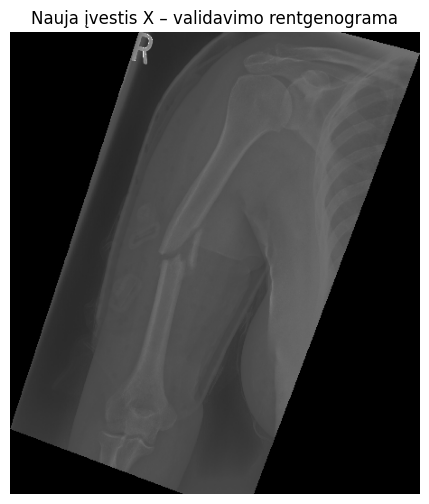

Tikroji klasė naudojama tik galutiniam rezultato patikrinimui.
Tikroji y reikšmė: 1


In [6]:
from PIL import Image
import matplotlib.pyplot as plt

query_image = Image.open(query_image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(query_image, cmap="gray")
plt.axis("off")
plt.title("Nauja įvestis X – validavimo rentgenograma")
plt.show()

print("Tikroji klasė naudojama tik galutiniam rezultato patikrinimui.")
print(f"Tikroji y reikšmė: {query_true_y}")

## 3. Vaizdų embeddingų kūrimas

Kiekviena rentgenograma paverčiama skaitiniu 512 reikšmių vektoriumi – embeddingu. Tam naudojamas iš anksto apmokytas `ResNet18` neuroninis tinklas. Panašių rentgenogramų embeddingai vektorių erdvėje yra arčiau vienas kito.

Embeddingai normalizuojami ir vėliau įrašomi į „ChromaDB“ kartu su žinomomis klasėmis `y`.

In [7]:
!pip install -q chromadb

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 588.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 44.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.7/95.7 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.6/60.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/

In [8]:
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Naudojamas įrenginys: {device}")

# Iš anksto apmokyto ResNet18 paruošimas
weights = ResNet18_Weights.DEFAULT
embedding_model = resnet18(weights=weights)

# Pašalinamas klasifikavimo sluoksnis
embedding_model.fc = torch.nn.Identity()
embedding_model = embedding_model.to(device)
embedding_model.eval()

image_transform = weights.transforms()


class HumerusDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        image_path = self.dataframe.iloc[index]["X"]
        image = Image.open(image_path).convert("RGB")
        image = self.transform(image)
        return image


rag_dataset = HumerusDataset(rag_df, image_transform)

rag_loader = DataLoader(
    rag_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

all_embeddings = []

with torch.inference_mode():
    for image_batch in tqdm(rag_loader, desc="Kuriami embeddingai"):
        image_batch = image_batch.to(device)

        embeddings = embedding_model(image_batch)

        # Vektorių normalizavimas
        embeddings = torch.nn.functional.normalize(
            embeddings, p=2, dim=1
        )

        all_embeddings.append(embeddings.cpu().numpy())

rag_embeddings = np.vstack(all_embeddings).astype("float32")

print("\n✅ Embeddingai sukurti.")
print(f"Pavyzdžių skaičius: {rag_embeddings.shape[0]}")
print(f"Vieno embeddingo dydis: {rag_embeddings.shape[1]}")

Naudojamas įrenginys: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 189MB/s]


Kuriami embeddingai:   0%|          | 0/32 [00:00<?, ?it/s]


✅ Embeddingai sukurti.
Pavyzdžių skaičius: 1000
Vieno embeddingo dydis: 512


## 4. Pavyzdžių saugojimas „ChromaDB“

Šiame etape 1 000 rentgenogramų embeddingų įrašomi į „ChromaDB“ vektorių duomenų bazę. Kartu su kiekvienu embeddingu saugomas:

- unikalus pavyzdžio ID;
- rentgenogramos failo kelias;
- žinoma klasė `y`;
- klasės reikšmė;
- duomenų rinkinio dalis.

Duomenų bazė išsaugoma „Google Drive“, todėl jos nereikės kurti iš naujo kiekvieną kartą paleidus notebooką.

In [9]:
import chromadb
from pathlib import Path

# ChromaDB saugojimo vieta Google Drive
CHROMA_DIR = Path(
    "/content/drive/MyDrive/Magistras/chroma_humerus_db"
)
CHROMA_DIR.mkdir(parents=True, exist_ok=True)

# Sukuriamas nuolatinis ChromaDB klientas
chroma_client = chromadb.PersistentClient(
    path=str(CHROMA_DIR)
)

# Sukuriama arba atidaroma kolekcija
collection = chroma_client.get_or_create_collection(
    name="mura_humerus_rag",
    metadata={"description": "1000 MURA XR_HUMERUS vaizdų embeddingų"}
)

ids = rag_df["id"].astype(str).tolist()

documents = [
    (
        f"Žastikaulio rentgenograma. "
        f"y = {int(row.y)}. "
        f"Rezultatas: {row.reiksme}."
    )
    for row in rag_df.itertuples()
]

metadatas = [
    {
        "image_path": str(row.X),
        "y": int(row.y),
        "reiksme": str(row.reiksme),
        "split": str(row.split)
    }
    for row in rag_df.itertuples()
]

# Duomenys įrašomi dalimis
batch_size = 200

for start in range(0, len(rag_df), batch_size):
    end = min(start + batch_size, len(rag_df))

    collection.upsert(
        ids=ids[start:end],
        embeddings=rag_embeddings[start:end].tolist(),
        documents=documents[start:end],
        metadatas=metadatas[start:end]
    )

    print(f"Įrašyta: {end}/{len(rag_df)}")

# Išsaugomas ir duomenų sąrašas
manifest_path = CHROMA_DIR / "rag_examples.csv"
rag_df.to_csv(manifest_path, index=False)

print("\n✅ Duomenys įrašyti į ChromaDB.")
print(f"Kolekcijos pavadinimas: {collection.name}")
print(f"Įrašų skaičius: {collection.count()}")
print(f"Duomenų bazės vieta: {CHROMA_DIR}")
print(f"Pavyzdžių sąrašas: {manifest_path}")

Įrašyta: 200/1000
Įrašyta: 400/1000
Įrašyta: 600/1000
Įrašyta: 800/1000
Įrašyta: 1000/1000

✅ Duomenys įrašyti į ChromaDB.
Kolekcijos pavadinimas: mura_humerus_rag
Įrašų skaičius: 1000
Duomenų bazės vieta: /content/drive/MyDrive/Magistras/chroma_humerus_db
Pavyzdžių sąrašas: /content/drive/MyDrive/Magistras/chroma_humerus_db/rag_examples.csv


## 5. Trijų panašiausių pavyzdžių paieška

Naujai įvesties rentgenogramai `X` sukuriamas embeddingas naudojant tą patį `ResNet18` modelį. Šis embeddingas perduodamas „ChromaDB“, kuri palygina jį su 1 000 duomenų bazėje saugomų embeddingų.

Sistema automatiškai grąžina tris mažiausią vektorinį atstumą turinčius `(X, y)` pavyzdžius. Kuo mažesnis atstumas, tuo vaizdai laikomi panašesniais.

In [10]:
# Naujos įvesties X embeddingo sukūrimas
query_image = Image.open(query_image_path).convert("RGB")
query_tensor = image_transform(query_image).unsqueeze(0).to(device)

with torch.inference_mode():
    query_embedding = embedding_model(query_tensor)

    query_embedding = torch.nn.functional.normalize(
        query_embedding, p=2, dim=1
    )

query_embedding = query_embedding.cpu().numpy().astype("float32")

print("✅ Naujos įvesties X embeddingas sukurtas.")
print(f"Embeddingo dydis: {query_embedding.shape}")

✅ Naujos įvesties X embeddingas sukurtas.
Embeddingo dydis: (1, 512)


In [11]:
# ChromaDB paieška
retrieval_results = collection.query(
    query_embeddings=query_embedding.tolist(),
    n_results=3,
    include=["metadatas", "documents", "distances"]
)

retrieved_ids = retrieval_results["ids"][0]
retrieved_metadata = retrieval_results["metadatas"][0]
retrieved_documents = retrieval_results["documents"][0]
retrieved_distances = retrieval_results["distances"][0]

retrieved_rows = []

for rank, (example_id, metadata, document, distance) in enumerate(
    zip(
        retrieved_ids,
        retrieved_metadata,
        retrieved_documents,
        retrieved_distances
    ),
    start=1
):
    retrieved_rows.append({
        "Vieta": rank,
        "ID": example_id,
        "y": metadata["y"],
        "Reikšmė": metadata["reiksme"],
        "Atstumas": round(float(distance), 4),
        "Failas": metadata["image_path"]
    })

retrieved_df = pd.DataFrame(retrieved_rows)

print("✅ Surasti 3 panašiausi pavyzdžiai:")
display(retrieved_df)

✅ Surasti 3 panašiausi pavyzdžiai:


,Vieta,ID,y,Reikšmė,Atstumas,Failas
0,1,humerus_0332,0,anomalijos nėra,0.1551,/content/drive/MyDrive/Magistras/Dataset/MURA-...
1,2,humerus_0278,1,anomalija,0.1601,/content/drive/MyDrive/Magistras/Dataset/MURA-...
2,3,humerus_0927,1,anomalija,0.1738,/content/drive/MyDrive/Magistras/Dataset/MURA-...


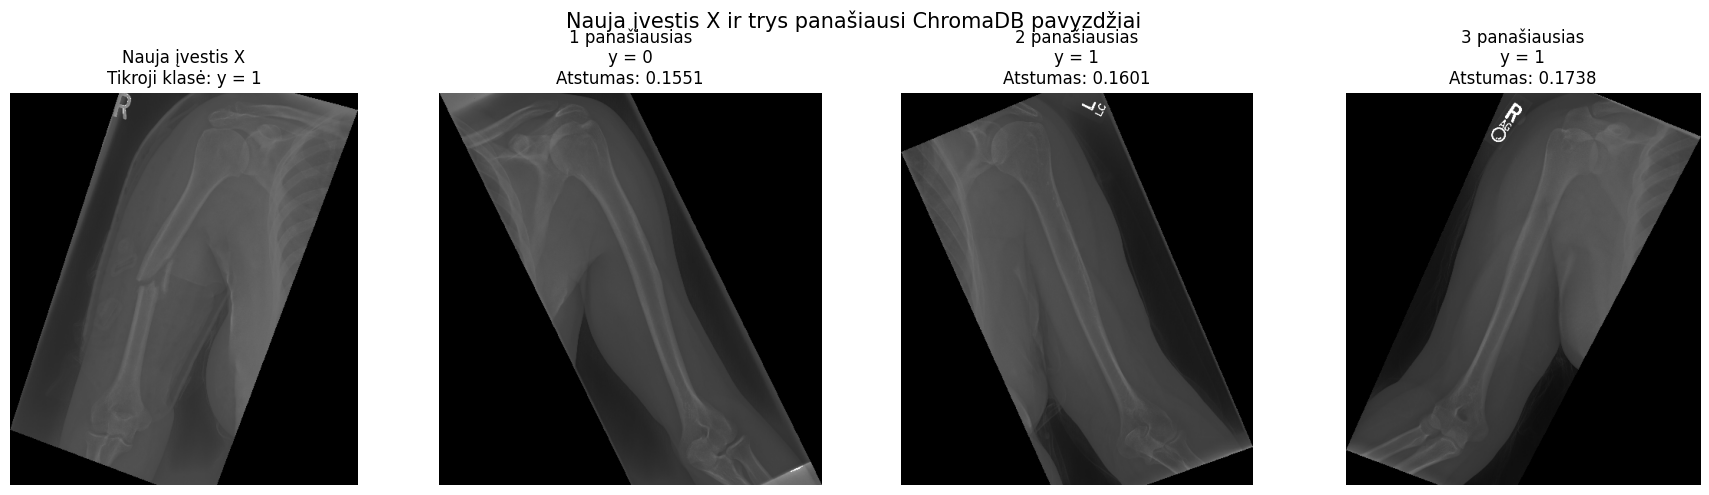

Paieškos rezultatai:
1. humerus_0332: y = 0, anomalijos nėra, atstumas = 0.1551
2. humerus_0278: y = 1, anomalija, atstumas = 0.1601
3. humerus_0927: y = 1, anomalija, atstumas = 0.1738


In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

# Nauja įvestis X
axes[0].imshow(query_image, cmap="gray")
axes[0].set_title(
    f"Nauja įvestis X\nTikroji klasė: y = {query_true_y}"
)
axes[0].axis("off")

# Trys ChromaDB surasti pavyzdžiai
for index, row in retrieved_df.iterrows():
    retrieved_image = Image.open(row["Failas"]).convert("RGB")

    axes[index + 1].imshow(retrieved_image, cmap="gray")
    axes[index + 1].set_title(
        f"{index + 1} panašiausias\n"
        f"y = {row['y']}\n"
        f"Atstumas: {row['Atstumas']}"
    )
    axes[index + 1].axis("off")

plt.suptitle(
    "Nauja įvestis X ir trys panašiausi ChromaDB pavyzdžiai",
    fontsize=15
)
plt.tight_layout()
plt.show()

print("Paieškos rezultatai:")
for _, row in retrieved_df.iterrows():
    print(
        f"{row['Vieta']}. {row['ID']}: "
        f"y = {row['y']}, {row['Reikšmė']}, "
        f"atstumas = {row['Atstumas']}"
    )

## 6. RAG prompto formavimas ir „Gemini API“ vykdymas

Trys „ChromaDB“ surasti pavyzdžiai naudojami kaip kontekstas naujos rentgenogramos analizei. Į „Gemini“ užklausą įtraukiami panašių pavyzdžių vaizdai, jų žinomos klasės `y` ir vektoriniai atstumai.

Taip galutinis modelio atsakymas grindžiamas ne tik nauju vaizdu, bet ir iš duomenų bazės automatiškai atrinktu kontekstu.

In [13]:
!pip install -q -U google-genai

from google.colab import userdata
from google import genai
from google.genai import types, errors

GEMINI_KEY = userdata.get("GEMINI_KEY")

if not GEMINI_KEY:
    raise ValueError(
        "Colab Secrets saugykloje nerastas GEMINI_KEY."
    )

client = genai.Client(api_key=GEMINI_KEY)

print("✅ Gemini API klientas paruoštas.")
print("🔒 API raktas kode nerodomas.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.9/267.9 kB 29.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.1 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
✅ Gemini API klientas paruoštas.
🔒 API raktas kode nerodomas.


In [14]:
# Automatiškai suformuojama trijų rastų pavyzdžių suvestinė
retrieved_context_lines = []

for _, row in retrieved_df.iterrows():
    retrieved_context_lines.append(
        f"{int(row['Vieta'])} pavyzdys: "
        f"y = {int(row['y'])}, "
        f"reikšmė = {row['Reikšmė']}, "
        f"vektorinis atstumas = {row['Atstumas']}."
    )

retrieved_context = "\n".join(retrieved_context_lines)

rag_prompt = f"""
Tu esi mokomasis dirbtinio intelekto agentas, analizuojantis
žastikaulio rentgenogramas.

Prieš naujos įvesties analizę ChromaDB iš 1 000 pavyzdžių
automatiškai atrinko tris vizualiai panašiausias rentgenogramas.

Atrinktų pavyzdžių žinomi rezultatai:
{retrieved_context}

Toliau tau pateikiami šių trijų pavyzdžių vaizdai ir jų klasės.
Po jų pateikiama nauja rentgenograma X.

Klasės:
- y = 0 – MURA duomenyse anomalijos nėra;
- y = 1 – MURA duomenyse pažymėta anomalija.

Atlik šiuos etapus:
1. Suprask naujos rentgenogramos turinį ir įvertink jos kokybę.
2. Palygink ją su trimis atrinktais pavyzdžiais.
3. Nustatyk, ar labiau tikėtina klasė y = 0 ar y = 1.
4. Nurodyk, ar matomi galimo lūžio požymiai.
5. Pateik trumpą sprendimą pagrindžiančių požymių suvestinę.
6. Sugeneruok galutinį rezultatą Y.

Atsakyk tik JSON formatu:

{{
  "duomenu_supratimas": {{
    "vaizdo_tipas": "žastikaulio rentgenograma",
    "vaizdo_kokybe": "tinkama, ribota arba netinkama"
  }},
  "rag_kontekstas": {{
    "panaudotu_pavyzdziu_skaicius": 3,
    "pavyzdziu_klases": [0, 1, 1],
    "konteksto_isvada": "trumpa išvada apie rastus pavyzdžius"
  }},
  "inference": {{
    "galima_anomalija": true,
    "galimas_luzis": true,
    "pasitikejimas": "žemas, vidutinis arba aukštas"
  }},
  "trumpas_paaiskinimas": "trumpa matomų požymių suvestinė",
  "Y": {{
    "klase": 0,
    "reiksme": "anomalijos nėra arba anomalija"
  }},
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}}

Neišgalvok koordinačių. MURA klasė y = 1 reiškia anomaliją ir
nebūtinai visais atvejais patvirtintą lūžį.
"""

print("✅ Papildytas RAG promptas sukurtas.\n")
print(rag_prompt)

✅ Papildytas RAG promptas sukurtas.


Tu esi mokomasis dirbtinio intelekto agentas, analizuojantis
žastikaulio rentgenogramas.

Prieš naujos įvesties analizę ChromaDB iš 1 000 pavyzdžių
automatiškai atrinko tris vizualiai panašiausias rentgenogramas.

Atrinktų pavyzdžių žinomi rezultatai:
1 pavyzdys: y = 0, reikšmė = anomalijos nėra, vektorinis atstumas = 0.1551.
2 pavyzdys: y = 1, reikšmė = anomalija, vektorinis atstumas = 0.1601.
3 pavyzdys: y = 1, reikšmė = anomalija, vektorinis atstumas = 0.1738.

Toliau tau pateikiami šių trijų pavyzdžių vaizdai ir jų klasės.
Po jų pateikiama nauja rentgenograma X.

Klasės:
- y = 0 – MURA duomenyse anomalijos nėra;
- y = 1 – MURA duomenyse pažymėta anomalija.

Atlik šiuos etapus:
1. Suprask naujos rentgenogramos turinį ir įvertink jos kokybę.
2. Palygink ją su trimis atrinktais pavyzdžiais.
3. Nustatyk, ar labiau tikėtina klasė y = 0 ar y = 1.
4. Nurodyk, ar matomi galimo lūžio požymiai.
5. Pateik trumpą sprendimą pagrindžiančių požymių suvestinę.

In [15]:
import json
import time

# Paruošiami trys ChromaDB atrinkti vaizdai
retrieved_images = [
    Image.open(path).convert("RGB")
    for path in retrieved_df["Failas"]
]

# Promptas papildomas realiais rastų pavyzdžių vaizdais
gemini_contents = [
    rag_prompt,

    "1 panašiausias pavyzdys, žinoma klasė "
    f"y = {int(retrieved_df.iloc[0]['y'])}:",
    retrieved_images[0],

    "2 panašiausias pavyzdys, žinoma klasė "
    f"y = {int(retrieved_df.iloc[1]['y'])}:",
    retrieved_images[1],

    "3 panašiausias pavyzdys, žinoma klasė "
    f"y = {int(retrieved_df.iloc[2]['y'])}:",
    retrieved_images[2],

    "Dabar išanalizuok šią naują įvestį X:",
    query_image
]

print("1 etapas – gauta nauja įvestis X.")
print("2 etapas – ChromaDB atrinko 3 panašiausius pavyzdžius.")
print("3 etapas – suformuotas papildytas RAG promptas.")
print("4 etapas – vykdoma Gemini analizė.")

for bandymas in range(5):
    try:
        rag_response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=gemini_contents,
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                temperature=0.2
            )
        )
        break

    except errors.ServerError:
        if bandymas == 4:
            raise

        print("Gemini laikinai užimtas. Užklausa kartojama...")
        time.sleep(5)

rag_result_y = json.loads(rag_response.text)

print("5 etapas – sugeneruotas galutinis rezultatas Y.")
print("\nRAG REZULTATAS Y:\n")
print(json.dumps(rag_result_y, ensure_ascii=False, indent=2))

print("\nRezultato patikrinimas:")
print(f"Gemini prognozė: y = {rag_result_y['Y']['klase']}")
print(f"Tikroji MURA klasė: y = {query_true_y}")

1 etapas – gauta nauja įvestis X.
2 etapas – ChromaDB atrinko 3 panašiausius pavyzdžius.
3 etapas – suformuotas papildytas RAG promptas.
4 etapas – vykdoma Gemini analizė.
5 etapas – sugeneruotas galutinis rezultatas Y.

RAG REZULTATAS Y:

{
  "duomenu_supratimas": {
    "vaizdo_tipas": "žastikaulio rentgenograma",
    "vaizdo_kokybe": "tinkama"
  },
  "rag_kontekstas": {
    "panaudotu_pavyzdziu_skaicius": 3,
    "pavyzdziu_klases": [
      0,
      1,
      1
    ],
    "konteksto_isvada": "Dauguma artimiausių kaimynų (2 iš 3) atitinka anomalijos klasę (y = 1)."
  },
  "inference": {
    "galima_anomalija": true,
    "galimas_luzis": true,
    "pasitikejimas": "aukštas"
  },
  "trumpas_paaiskinimas": "Rentgenogramoje matomas ryškus diafizinis žastikaulio lūžis su ženkliu kaulinių fragmentų poslinkiu bei ašies iškrypimu.",
  "Y": {
    "klase": 1,
    "reiksme": "anomalija"
  },
  "perspejimas": "Rezultatas skirtas tik mokymosi ir tyrimo tikslams, o ne medicininei diagnozei."
}

Rezul

## 7. Galutinio RAG proceso ir rezultato vizualizacija

Toliau vizualizuojama visa end-to-end RAG proceso eiga – nuo naujos rentgenogramos gavimo iki galutinio rezultato `Y`. Taip pat pateikiama rezultatų suvestinė, leidžianti palyginti RAG prognozę su tikrąja MURA klase.

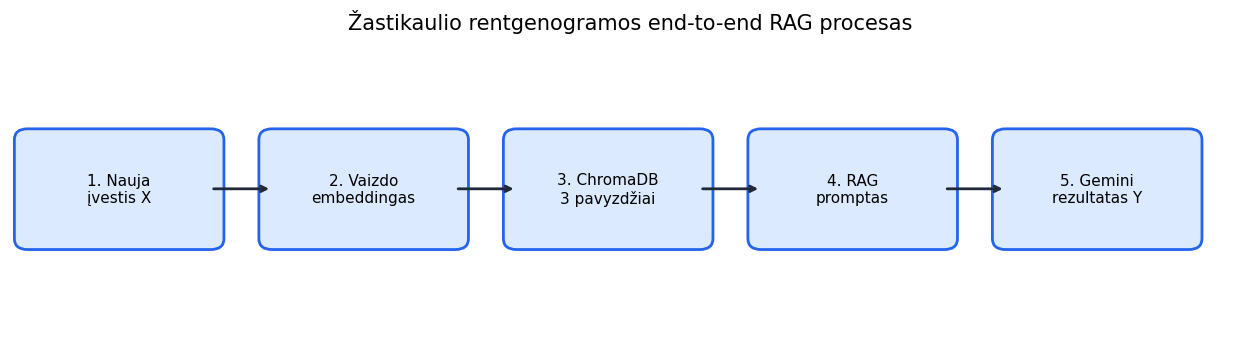

GALUTINĖ RAG REZULTATŲ SUVESTINĖ:


,Duomenų bazės dydis,Rastų pavyzdžių klasės,Gemini prognozė Y,Tikroji klasė y,Prognozė teisinga,Pasitikėjimas
0,1000,"[0, 1, 1]",1,1,True,aukštas


In [16]:
from matplotlib.patches import FancyBboxPatch
import matplotlib.pyplot as plt
import pandas as pd

stages = [
    "1. Nauja\nįvestis X",
    "2. Vaizdo\nembeddingas",
    "3. ChromaDB\n3 pavyzdžiai",
    "4. RAG\npromptas",
    "5. Gemini\nrezultatas Y"
]

positions = [0.2, 3.0, 5.8, 8.6, 11.4]

fig, ax = plt.subplots(figsize=(16, 3.8))
ax.set_xlim(0, 14.2)
ax.set_ylim(0, 4)
ax.axis("off")

for index, (stage, x_position) in enumerate(zip(stages, positions)):
    box = FancyBboxPatch(
        (x_position, 1.25),
        2.1,
        1.35,
        boxstyle="round,pad=0.15",
        facecolor="#dbeafe",
        edgecolor="#2563eb",
        linewidth=2
    )
    ax.add_patch(box)

    ax.text(
        x_position + 1.05,
        1.93,
        stage,
        ha="center",
        va="center",
        fontsize=11
    )

    if index < len(stages) - 1:
        ax.annotate(
            "",
            xy=(positions[index + 1], 1.93),
            xytext=(x_position + 2.1, 1.93),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=2,
                color="#1f2937"
            )
        )

plt.title(
    "Žastikaulio rentgenogramos end-to-end RAG procesas",
    fontsize=15
)
plt.show()

# Galutinė rezultatų suvestinė
final_summary = pd.DataFrame([{
    "Duomenų bazės dydis": collection.count(),
    "Rastų pavyzdžių klasės": str(
        retrieved_df["y"].astype(int).tolist()
    ),
    "Gemini prognozė Y": int(rag_result_y["Y"]["klase"]),
    "Tikroji klasė y": query_true_y,
    "Prognozė teisinga": (
        int(rag_result_y["Y"]["klase"]) == query_true_y
    ),
    "Pasitikėjimas": rag_result_y["inference"]["pasitikejimas"]
}])

print("GALUTINĖ RAG REZULTATŲ SUVESTINĖ:")
display(final_summary)

## 8. Refleksija

Sukurta RAG sistema išplečia ankstesnį end-to-end DI agentą, įtraukdama panašių pavyzdžių paiešką. „ChromaDB“ duomenų bazėje buvo išsaugota 1 000 žastikaulio rentgenogramų embeddingų ir jų žinomos klasės. Naujai įvesties rentgenogramai sistema automatiškai surado tris vizualiai panašiausius pavyzdžius. Du iš trijų atrinktų pavyzdžių priklausė anomalijos klasei, todėl jie suteikė papildomą kontekstą „Gemini“ modeliui. Papildytame prompte buvo panaudoti atrinktų pavyzdžių vaizdai, jų klasės ir vektoriniai atstumai. „Gemini“ nustatė anomaliją ir galimo diafizinio lūžio požymius bei sugeneravo klasę `Y = 1`. Ši prognozė sutapo su tikrąja MURA klase, todėl šiame pavyzdyje RAG suteikė tinkamą papildomą kontekstą ir padidino sprendimo pagrįstumą. Vis dėlto vieno pavyzdžio nepakanka statistiškai įrodyti tikslumo pagerėjimą, todėl ateityje sistemą reikėtų įvertinti su didesniu validavimo rinkiniu. Sistemą taip pat būtų galima patobulinti embeddingams naudojant specialiai medicininėms rentgenogramoms apmokytą modelį.